# Landweber iteration and discrepancy principle
In this lab, you should solve a three-dimensional tomography problem with the Landweber method. Have a look at the lecture slides to see how this method should work. 

* Start by initializing an appropriate discretized space, in this case a three-dimensional function space centered at (0,0,0), starting with $32 \times 32 \times 32$ resolution for testing. Pass ``dtype='float32'``, which the ASTRA backend requires in ODL 1.0.

* Create a three-dimensional [Shepp–Logan phantom](https://odl.readthedocs.io/generated/odl.core.phantom.transmission.shepp_logan.html) in the space by calling ``odl.phantom.transmission.shepp_logan(Space, modified=True)`` (noting that the modified phantom has much higher contrast than the unmodified version). Make sure that the phantom is centered at the origin with the ``show`` method (this only shows a slice of this 3D function). 

* Form the forward operator for the ray transform with a [cone beam geometry](https://odl.readthedocs.io/generated/odl.applications.tomo.geometry.conebeam.cone_beam_geometry.html) (you can call ``odl.applications.tomo.cone_beam_geometry``) with a small number $(\sim 10)$ of angles, otherwise you will not see the effects of semi-convergence. 

* Apply the forward operator to the phantom to obtain the sinogram, then add some noise to it (note that the sinogram lives in ``Operator.range``).

* You can obtain the norm of a vector with its [norm method](https://odl.readthedocs.io/generated/odl.DiscretizedSpaceElement.norm.html). For the discrepancy of the Landweber method, you will also need the absolute noise level $\| g - g_{\mathrm{noisy}}\|$ of the sinogram $g$ (in real applications you must estimate the noise level somehow).

* You can obtain an estimate of the largest singular value of the forward operator with its [norm method](https://odl.readthedocs.io/generated/odl.Operator.norm.html). Note that this is operator norm, which may need to be estimated (by odl) if the relevant space does not have an analytic method for calculating it.

* The adjoint of the forward operator is given by ``Operator.adjoint``.

* Implement the Landweber method as a function and employ $\sim 200$ iterations to obtain a solution for the noisy sinogram, starting with the [zero vector](https://odl.readthedocs.io/generated/odl.DiscretizedSpace.zero.html) as your initial guess.

* Log the pertinent norms between iterations and check when the discrepancy criterion is satisfied (but do not stop the iteration).

* Plot the relative error of your reconstructions against the number of iterations and check when the discrepancy criterion would have stopped the iterations: what would it have given you?

* Use the ``show`` method to inspect your best reconstruction and compare it with the original phantom. Since this is a 3D function, you should also try to show different slices and perspectives (check the documentation for details).

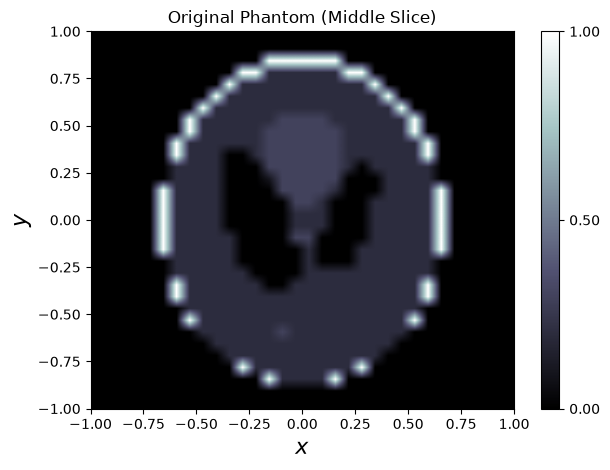

<Figure size 640x480 with 0 Axes>

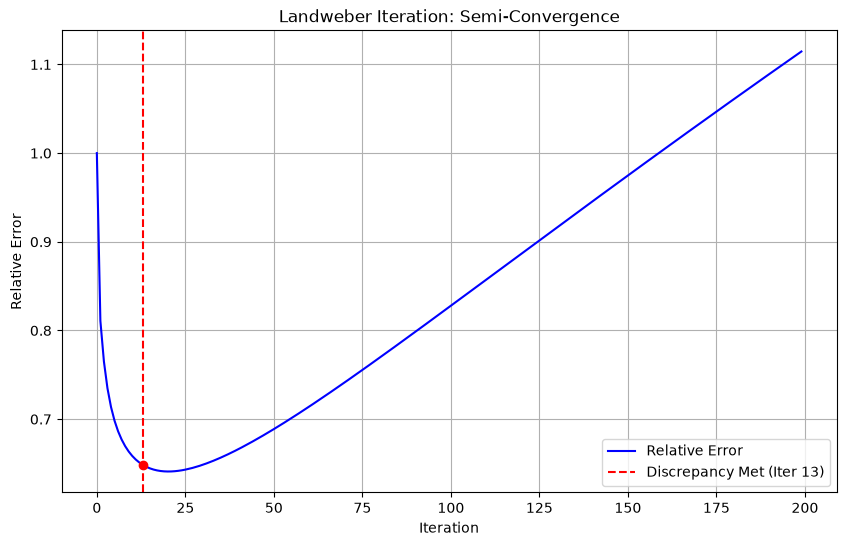

Discrepancy principle met at iteration 13 (Relative Error: 0.6484)


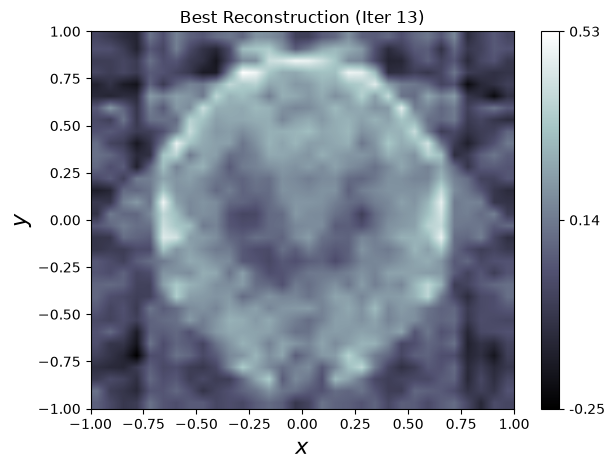

<Figure size 640x480 with 0 Axes>

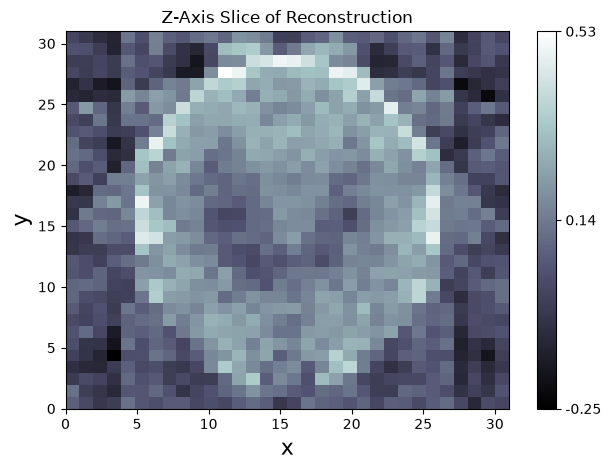

<Figure size 640x480 with 0 Axes>

In [1]:
import odl
import odl.applications.tomo
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize the 3D space centered at (0, 0, 0)
space = odl.uniform_discr([-1, -1, -1], [1, 1, 1], shape=(32, 32, 32), dtype='float32')

# 2. Create the 3D modified Shepp-Logan phantom
phantom = odl.phantom.shepp_logan(space, modified=True)
phantom.show(title="Original Phantom (Middle Slice)", force_show=True)

# 3. Form the forward operator with cone-beam geometry
geometry = odl.applications.tomo.cone_beam_geometry(
    space, 
    src_radius=3, 
    det_radius=3, 
    num_angles=10
)
operator = odl.applications.tomo.RayTransform(space, geometry)

# 4. Generate the sinogram and add Gaussian white noise
g_exact = operator(phantom)
noise = odl.phantom.noise.white_noise(operator.range)
noise_level = 0.05 * odl.max(odl.abs(g_exact))
g_noisy = g_exact + noise_level * noise

# 5. Calculate absolute noise level for the discrepancy principle
delta = (g_exact - g_noisy).norm()

# 6. Estimate operator norm and set step size (omega)
op_norm = operator.norm(estimate=True)
omega = 1.0 / (op_norm ** 2)

# 7. Initialize Landweber variables
x = space.zero()
n_iter = 200
tau = 1.05  
stopping_discrepancy = tau * delta

rel_errors = []
discrepancies = []
stop_iter = None
x_opt = None

# 8 & 9. Landweber Iteration Loop
for i in range(n_iter):
    Ax = operator(x)
    residual = Ax - g_noisy
    
    current_discrepancy = residual.norm()
    discrepancies.append(current_discrepancy)
    
    current_rel_error = (x - phantom).norm() / phantom.norm()
    rel_errors.append(current_rel_error)
    
    if stop_iter is None and current_discrepancy <= stopping_discrepancy:
        stop_iter = i
        x_opt = x.copy()  
        
    # Updated: Out-of-place assignment prevents ODL 1.0 array coercion errors
    x = x - float(omega) * operator.adjoint(residual)

# 10. Plotting the relative error and marking the discrepancy point
plt.figure(figsize=(10, 6))
plt.plot(range(n_iter), rel_errors, label="Relative Error", color='blue')

if stop_iter is not None:
    plt.axvline(x=stop_iter, color='red', linestyle='--', label=f"Discrepancy Met (Iter {stop_iter})")
    plt.plot(stop_iter, rel_errors[stop_iter], 'ro')
    
plt.xlabel("Iteration")
plt.ylabel("Relative Error")
plt.title("Landweber Iteration: Semi-Convergence")
plt.legend()
plt.grid(True)
plt.show()

# 11. Visualizing the optimal reconstruction
if stop_iter is not None:
    print(f"Discrepancy principle met at iteration {stop_iter} (Relative Error: {rel_errors[stop_iter]:.4f})")
    x_opt.show(title=f"Best Reconstruction (Iter {stop_iter})", force_show=True)
    x_opt[:, :, 16].show(title=f"Z-Axis Slice of Reconstruction", force_show=True)
else:
    print("Discrepancy principle was not met within the assigned iterations.")
    x.show(title="Reconstruction at Iteration 200", force_show=True)